# Notebook 2: RNN in PyTorch and the Vanishing Gradient
**Phase 3, Day 2**

In this notebook: (1) an RNN forecaster compared with the naive baseline, (2) a vanishing-gradient demo, (3) a long-memory task where the RNN fails.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn

torch.manual_seed(42)
np.random.seed(42)

## Part 1: Data (same as Day 1)

In [2]:
n = 1000
t = np.arange(n)
series = np.sin(2 * np.pi * t / 50) + 0.1 * np.random.randn(n)

n_train, n_val = int(0.70 * n), int(0.15 * n)
train_raw = series[:n_train]
val_raw   = series[n_train:n_train + n_val]
test_raw  = series[n_train + n_val:]

mean, std = train_raw.mean(), train_raw.std()
train, val, test = [(a - mean) / std for a in (train_raw, val_raw, test_raw)]

def make_windows(data, k):
    X = np.array([data[i:i + k] for i in range(len(data) - k)])
    y = np.array([data[i + k] for i in range(len(data) - k)])
    return X, y

k = 20
def to_tensors(d):
    X, y = make_windows(d, k)
    # RNN input shape: (batch, time, features)
    return (torch.tensor(X, dtype=torch.float32).unsqueeze(-1),
            torch.tensor(y, dtype=torch.float32).unsqueeze(-1))

X_train, y_train = to_tensors(train)
X_val,   y_val   = to_tensors(val)
X_test,  y_test  = to_tensors(test)
print(X_train.shape, y_train.shape)

torch.Size([680, 20, 1]) torch.Size([680, 1])


## Part 2: A many-to-one RNN model
`nn.RNN` with `batch_first=True` returns output of shape `(batch, time, hidden)`. The hidden state of the last time step goes into `nn.Linear`.

In [3]:
class RNNForecaster(nn.Module):
    def __init__(self, input_size=1, hidden_size=32):
        super().__init__()
        self.rnn = nn.RNN(input_size, hidden_size, batch_first=True)
        self.fc = nn.Linear(hidden_size, 1)

    def forward(self, x):
        out, h_n = self.rnn(x)        # out: (B, T, H), h_n: (1, B, H)
        return self.fc(out[:, -1, :]) # last time step

model = RNNForecaster()
print(model)
print("Parameters:", sum(p.numel() for p in model.parameters()))

RNNForecaster(
  (rnn): RNN(1, 32, batch_first=True)
  (fc): Linear(in_features=32, out_features=1, bias=True)
)
Parameters: 1153


epoch  5  train=0.0369  val=0.0322
epoch 10  train=0.0321  val=0.0300
epoch 15  train=0.0285  val=0.0257
epoch 20  train=0.0258  val=0.0249
epoch 25  train=0.0257  val=0.0231
epoch 30  train=0.0246  val=0.0224


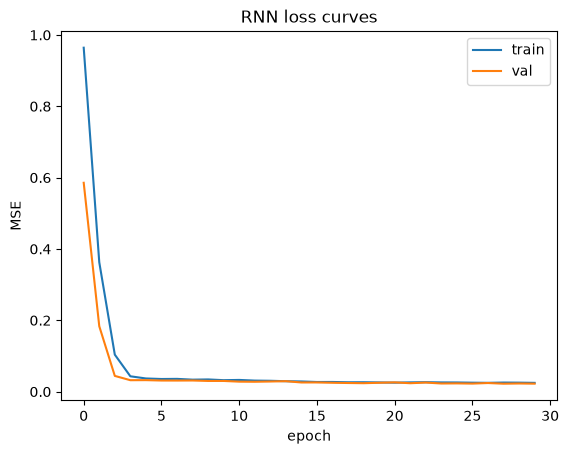

In [4]:
loss_fn = nn.MSELoss()
opt = torch.optim.Adam(model.parameters(), lr=1e-3)

epochs, bs = 30, 32
train_losses, val_losses = [], []

for ep in range(epochs):
    model.train()
    perm = torch.randperm(len(X_train))
    total = 0.0
    for i in range(0, len(perm), bs):
        idx = perm[i:i + bs]
        opt.zero_grad()
        loss = loss_fn(model(X_train[idx]), y_train[idx])
        loss.backward()
        # Gradient clipping: protects against exploding gradients
        nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
        opt.step()
        total += loss.item() * len(idx)
    train_losses.append(total / len(X_train))

    model.eval()
    with torch.no_grad():
        val_losses.append(loss_fn(model(X_val), y_val).item())
    if (ep + 1) % 5 == 0:
        print(f"epoch {ep+1:2d}  train={train_losses[-1]:.4f}  val={val_losses[-1]:.4f}")

plt.plot(train_losses, label='train'); plt.plot(val_losses, label='val')
plt.xlabel('epoch'); plt.ylabel('MSE'); plt.legend(); plt.title('RNN loss curves')
plt.show()

RNN   TEST: MAE=0.1175  RMSE=0.1450
Naive TEST: MAE=0.1762  RMSE=0.2247


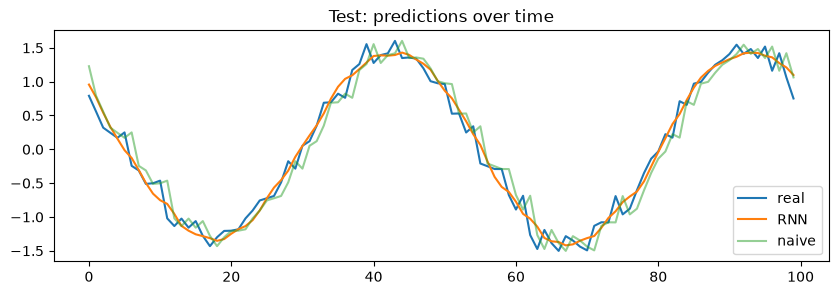

In [5]:
# RNN vs naive on the test set (both on the same scaled values)
model.eval()
with torch.no_grad():
    pred = model(X_test).squeeze().numpy()
real  = y_test.squeeze().numpy()
naive = X_test[:, -1, 0].numpy()

mae  = lambda a, b: np.mean(np.abs(a - b))
rmse = lambda a, b: np.sqrt(np.mean((a - b) ** 2))

print(f"RNN   TEST: MAE={mae(real, pred):.4f}  RMSE={rmse(real, pred):.4f}")
print(f"Naive TEST: MAE={mae(real, naive):.4f}  RMSE={rmse(real, naive):.4f}")

plt.figure(figsize=(10, 3))
plt.plot(real[:100], label='real')
plt.plot(pred[:100], label='RNN')
plt.plot(naive[:100], label='naive', alpha=0.5)
plt.legend(); plt.title('Test: predictions over time')
plt.show()

**Observation:** did the RNN beat the naive baseline? By how much? (write in your own words)

## Part 3: Vanishing gradient demo
We measure the gradient of the last output with respect to the input at **every earlier time step**. If the gradient gets smaller the further back we go, the RNN forgets the distant past.

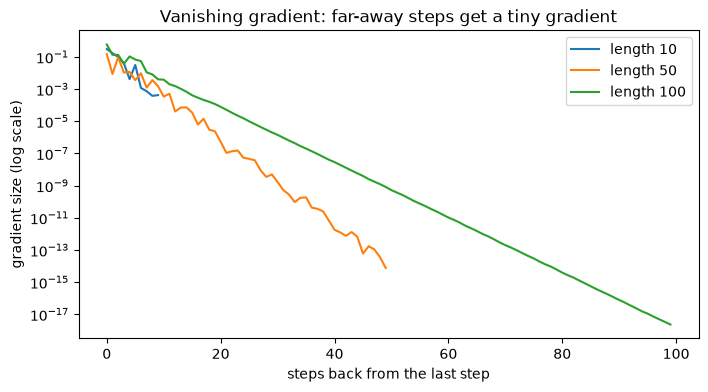

In [6]:
def grad_norms(seq_len, hidden=32, trials=20):
    rnn = nn.RNN(1, hidden, batch_first=True)   # default activation: tanh
    norms = torch.zeros(seq_len)
    for _ in range(trials):
        x = torch.randn(1, seq_len, 1, requires_grad=True)
        out, _ = rnn(x)
        out[:, -1, :].sum().backward()
        norms += x.grad.abs().squeeze()
    return (norms / trials).numpy()

plt.figure(figsize=(8, 4))
for L in (10, 50, 100):
    g = grad_norms(L)
    # x-axis: how many steps back from the last step
    plt.semilogy(np.arange(L)[::-1], g + 1e-30, label=f'length {L}')
plt.xlabel('steps back from the last step')
plt.ylabel('gradient size (log scale)')
plt.title('Vanishing gradient: far-away steps get a tiny gradient')
plt.legend(); plt.show()

**Observation:** the further back the time step, the smaller the gradient. This is why a plain RNN cannot learn long dependencies.

## Part 4: A task where the RNN fails
Sequence length 50, label = **was the first element positive?** The other 49 elements are noise, so the model must remember something from very far back. Random guessing = 50% accuracy.

In [7]:
def memory_task(T, n=2000):
    x = torch.randn(n, T, 1)
    y = (x[:, 0, 0] > 0).float().unsqueeze(-1)
    return x, y

class RNNClassifier(nn.Module):
    def __init__(self, hidden=32):
        super().__init__()
        self.rnn = nn.RNN(1, hidden, batch_first=True)
        self.fc = nn.Linear(hidden, 1)
    def forward(self, x):
        out, _ = self.rnn(x)
        return self.fc(out[:, -1, :])   # logits

def train_memory(T, steps=300):
    torch.manual_seed(0)
    Xtr, ytr = memory_task(T)
    Xte, yte = memory_task(T, 1000)
    m = RNNClassifier()
    opt = torch.optim.Adam(m.parameters(), lr=1e-2)
    lf = nn.BCEWithLogitsLoss()
    for s in range(steps):
        idx = torch.randint(0, len(Xtr), (64,))
        opt.zero_grad()
        lf(m(Xtr[idx]), ytr[idx]).backward()
        nn.utils.clip_grad_norm_(m.parameters(), 1.0)
        opt.step()
    with torch.no_grad():
        acc = ((m(Xte) > 0).float() == yte).float().mean().item()
    return acc

for T in (5, 20, 50):
    print(f"Sequence length {T:2d}: test accuracy = {train_memory(T):.2f}")

Sequence length  5: test accuracy = 0.98
Sequence length 20: test accuracy = 0.98
Sequence length 50: test accuracy = 0.43


**Observation:** on short sequences the RNN does fine, but on long ones the accuracy drops towards 0.5 (random guessing). Exact numbers vary a little between runs. Tomorrow LSTM and GRU will solve this same task.

## Summary (write in your own words)
- Input/output shapes of `nn.RNN`:
- What BPTT and the vanishing gradient are:
- What gradient clipping protects against: